In [1]:
import torch
import pyro
import pyro.distributions as dist
from pyro.infer import SVI, Trace_ELBO, Predictive
from pyro.infer.autoguide import AutoNormal
from pyro.optim import ClippedAdam

pyro.clear_param_store()

torch.set_default_dtype(torch.float32)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

train_df = pd.read_parquet("airport_3min_train.parquet")
test_df = pd.read_parquet("airport_3min_test.parquet")

train_df["timestamp"] = pd.to_datetime(train_df["timestamp"], utc=True)
test_df["timestamp"] = pd.to_datetime(test_df["timestamp"], utc=True)

train_df.head()

,timestamp,ins,outs,total,outs_share,slot,weekday,month,is_weekend
0,2024-04-01 00:00:00+00:00,97.0,12.0,109.0,0.110092,0,0,3,0
1,2024-04-01 00:03:00+00:00,72.0,30.0,102.0,0.294118,1,0,3,0
2,2024-04-01 00:06:00+00:00,90.0,13.0,103.0,0.126214,2,0,3,0
3,2024-04-01 00:09:00+00:00,98.0,17.0,115.0,0.147826,3,0,3,0
4,2024-04-01 00:12:00+00:00,56.0,12.0,68.0,0.176471,4,0,3,0


# Model 1 - init

In [3]:
# Preparing tensors

train_df = train_df.sort_values("timestamp").reset_index(drop=True)
test_df = test_df.sort_values("timestamp").reset_index(drop=True)

slot_train = torch.tensor(train_df["slot"].values, dtype=torch.long)
total_train = torch.tensor(train_df["total"].values, dtype=torch.float32)
outs_train = torch.tensor(train_df["outs"].values, dtype=torch.float32)

slot_test = torch.tensor(test_df["slot"].values, dtype=torch.long)
total_test = torch.tensor(test_df["total"].values, dtype=torch.float32)
outs_test = torch.tensor(test_df["outs"].values, dtype=torch.float32)

In [6]:
def airport_model(slot, total_obs=None, outs_obs=None):
    n = len(slot)
    n_slots = 480

    mu = pyro.sample("mu", dist.Normal(5.5, 1.0))
    eta = pyro.sample("eta", dist.Normal(0.0, 1.0))

    sigma_slot_total = pyro.sample("sigma_slot_total", dist.HalfNormal(1.0))
    sigma_slot_dir = pyro.sample("sigma_slot_dir", dist.HalfNormal(1.0))

    phi = pyro.sample("phi", dist.HalfNormal(10.0))

    with pyro.plate("slots", n_slots):
        slot_total_raw = pyro.sample("slot_total_raw", dist.Normal(0.0, 1.0))
        slot_dir_raw = pyro.sample("slot_dir_raw", dist.Normal(0.0, 1.0))

    slot_total_effect = sigma_slot_total * slot_total_raw
    slot_dir_effect = sigma_slot_dir * slot_dir_raw

    log_lambda = mu + slot_total_effect[slot]
    lambda_ = torch.exp(log_lambda)

    logits_p = eta + slot_dir_effect[slot]

    with pyro.plate("data", n):

        total = pyro.sample(
            "total",
            dist.NegativeBinomial(
                total_count=phi,
                logits=torch.log(lambda_) - torch.log(phi)
            ),
            obs=total_obs
        )

        binomial_total = total_obs if total_obs is not None else total

        pyro.sample(
            "outs",
            dist.Binomial(
                total_count=binomial_total,
                logits=logits_p
            ),
            obs=outs_obs
        )

In [7]:
guide = AutoNormal(airport_model)

pyro.clear_param_store()


optimizer = ClippedAdam({"lr": 0.01, "clip_norm": 10.0})
svi = SVI(airport_model, guide, optimizer, loss=Trace_ELBO())

losses = []

num_steps = 3000

for step in range(num_steps):
    loss = svi.step(slot_train, total_train, outs_train)
    losses.append(loss / len(train_df))

    if step % 300 == 0:
        print(f"step {step:04d} | loss per obs = {losses[-1]:.2f}")

step 0000 | loss per obs = 53.29
step 0300 | loss per obs = 10.77
step 0600 | loss per obs = 10.73
step 0900 | loss per obs = 10.73
step 1200 | loss per obs = 10.73
step 1500 | loss per obs = 10.73
step 1800 | loss per obs = 10.73
step 2100 | loss per obs = 10.73
step 2400 | loss per obs = 10.73
step 2700 | loss per obs = 10.73


In [18]:
predictive = Predictive(
    airport_model,
    guide=guide,
    num_samples=500,
    return_sites=("total", "outs")
)

samples = predictive(slot_test, None, None)

total_samples = samples["total"].detach().cpu().numpy()
outs_samples = samples["outs"].detach().cpu().numpy()

total_pred_mean = total_samples.mean(axis=0)
outs_pred_mean = outs_samples.mean(axis=0)

test_df = test_df.copy()

test_df["pyro_total_mean"] = total_pred_mean
test_df["pyro_outs_mean"] = outs_pred_mean
test_df["pyro_ins_mean"] = test_df["pyro_total_mean"] - test_df["pyro_outs_mean"]
test_df["pyro_outs_share_mean"] = (
    test_df["pyro_outs_mean"] / np.maximum(test_df["pyro_total_mean"], 1)
)

test_df[[
    "total",
    "outs",
    "pyro_total_mean",
    "pyro_outs_mean",
    "pyro_ins_mean",
    "pyro_outs_share_mean"
]].head()

,total,outs,pyro_total_mean,pyro_outs_mean,pyro_ins_mean,pyro_outs_share_mean
0,51.0,25.0,92.092003,43.933998,48.158005,0.477066
1,76.0,36.0,103.038002,54.271999,48.766003,0.526718
2,38.0,5.0,91.157997,47.556000,43.601997,0.521688
3,61.0,37.0,89.608002,44.265999,45.342003,0.493996
4,53.0,38.0,96.419998,50.377998,46.042000,0.522485


In [20]:
print(test_df.shape)
print(total_samples.shape)
print(outs_samples.shape)

(65560, 25)
(500, 65560)
(500, 65560)


# Evaluating Pyro Model

In [25]:
def mae(y, yhat):
    return np.mean(np.abs(y - yhat))

def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat) ** 2))

pyro_metrics = {
    "total_mae": mae(test_df["total"], test_df["pyro_total_mean"]),
    "total_rmse": rmse(test_df["total"], test_df["pyro_total_mean"]),
    "outs_mae": mae(test_df["outs"], test_df["pyro_outs_mean"]),
    "outs_rmse": rmse(test_df["outs"], test_df["pyro_outs_mean"]),
    "ins_mae": mae(test_df["ins"], test_df["pyro_ins_mean"]),
    "ins_rmse": rmse(test_df["ins"], test_df["pyro_ins_mean"]),
    "direction_mae": mae(test_df["outs_share"], test_df["pyro_outs_share_mean"]),
}

true_direction = test_df["outs"] > test_df["ins"]
pred_direction = test_df["pyro_outs_mean"] > test_df["pyro_ins_mean"]

pyro_metrics["direction_accuracy"] = np.mean(true_direction == pred_direction)

pyro_metrics

{'total_mae': np.float64(23.754592924353698),
 'total_rmse': np.float64(30.256008019439097),
 'outs_mae': np.float64(17.002604603576472),
 'outs_rmse': np.float64(22.947295507714024),
 'ins_mae': np.float64(11.224933412458345),
 'ins_rmse': np.float64(14.745233303003657),
 'direction_mae': np.float64(0.18609804522935217),
 'direction_accuracy': np.float64(0.6722849298352654)}

In [26]:
baseline_results = pd.read_csv("baseline_results.csv", index_col=0)

comparison = baseline_results.copy()
comparison.loc["pyro_slot_model"] = pyro_metrics

comparison

,total_mae,total_rmse,outs_mae,outs_rmse,ins_mae,ins_rmse,direction_mae,direction_accuracy
global,31.144284,37.632649,22.237336,27.070677,16.414727,19.899338,0.222696,0.522773
slot,23.398850,29.866508,16.391825,22.595708,12.701343,15.734784,0.187874,0.664704
slot_weekday,21.045095,27.447879,14.858650,21.236757,11.559840,14.620317,0.174658,0.695500
pyro_slot_model,23.754593,30.256008,17.002605,22.947296,11.224933,14.745233,0.186098,0.672285


In [29]:
# Mean predictions
test_df["pyro_total_mean"] = total_samples.mean(axis=0)
test_df["pyro_outs_mean"] = outs_samples.mean(axis=0)

test_df["pyro_ins_mean"] = (
    test_df["pyro_total_mean"] - test_df["pyro_outs_mean"]
)

test_df["pyro_outs_share_mean"] = (
    test_df["pyro_outs_mean"] / np.maximum(test_df["pyro_total_mean"], 1)
)

# 90% posterior predictive intervals
test_df["pyro_total_q05"] = np.quantile(total_samples, 0.05, axis=0)
test_df["pyro_total_q95"] = np.quantile(total_samples, 0.95, axis=0)

test_df["pyro_outs_q05"] = np.quantile(outs_samples, 0.05, axis=0)
test_df["pyro_outs_q95"] = np.quantile(outs_samples, 0.95, axis=0)

# Out-share samples
outs_share_samples = outs_samples / np.maximum(total_samples, 1)

test_df["pyro_outs_share_q05"] = np.quantile(outs_share_samples, 0.05, axis=0)
test_df["pyro_outs_share_q95"] = np.quantile(outs_share_samples, 0.95, axis=0)

test_df[[
    "pyro_total_mean",
    "pyro_total_q05",
    "pyro_total_q95",
    "pyro_outs_mean",
    "pyro_outs_q05",
    "pyro_outs_q95",
]].head()

,pyro_total_mean,pyro_total_q05,pyro_total_q95,pyro_outs_mean,pyro_outs_q05,pyro_outs_q95
0,92.092003,21.000000,209.100006,43.933998,10.00,99.050003
1,103.038002,24.000000,224.050003,54.271999,12.95,123.150002
2,91.157997,22.950001,186.750000,47.556000,11.00,106.050003
3,89.608002,22.000000,197.149994,44.265999,11.00,94.000000
4,96.419998,27.950001,199.100006,50.377998,13.95,104.000000


In [28]:
total_coverage = np.mean(
    (test_df["total"] >= test_df["pyro_total_q05"]) &
    (test_df["total"] <= test_df["pyro_total_q95"])
)

outs_coverage = np.mean(
    (test_df["outs"] >= test_df["pyro_outs_q05"]) &
    (test_df["outs"] <= test_df["pyro_outs_q95"])
)

share_coverage = np.mean(
    (test_df["outs_share"] >= test_df["pyro_outs_share_q05"]) &
    (test_df["outs_share"] <= test_df["pyro_outs_share_q95"])
)

print(f"Total 90% coverage:      {total_coverage:.3f}")
print(f"Outs 90% coverage:       {outs_coverage:.3f}")
print(f"Out-share 90% coverage:  {share_coverage:.3f}")

Total 90% coverage:      0.897
Outs 90% coverage:       0.793
Out-share 90% coverage:  0.501


# Model 2: slot + weekday

In [30]:
weekday_train = torch.tensor(train_df["weekday"].values, dtype=torch.long)
weekday_test = torch.tensor(test_df["weekday"].values, dtype=torch.long)

def airport_model_slot_weekday(slot, weekday, total_obs=None, outs_obs=None):
    n = len(slot)
    n_slots = 480
    n_weekdays = 7

    mu = pyro.sample("mu", dist.Normal(5.5, 1.0))
    eta = pyro.sample("eta", dist.Normal(0.0, 1.0))

    sigma_slot_total = pyro.sample("sigma_slot_total", dist.HalfNormal(1.0))
    sigma_slot_dir = pyro.sample("sigma_slot_dir", dist.HalfNormal(1.0))

    sigma_weekday_total = pyro.sample("sigma_weekday_total", dist.HalfNormal(0.5))
    sigma_weekday_dir = pyro.sample("sigma_weekday_dir", dist.HalfNormal(0.5))

    phi = pyro.sample("phi", dist.HalfNormal(10.0))

    with pyro.plate("slots", n_slots):
        slot_total_raw = pyro.sample("slot_total_raw", dist.Normal(0.0, 1.0))
        slot_dir_raw = pyro.sample("slot_dir_raw", dist.Normal(0.0, 1.0))

    with pyro.plate("weekdays", n_weekdays):
        weekday_total_raw = pyro.sample("weekday_total_raw", dist.Normal(0.0, 1.0))
        weekday_dir_raw = pyro.sample("weekday_dir_raw", dist.Normal(0.0, 1.0))

    slot_total_effect = sigma_slot_total * slot_total_raw
    slot_dir_effect = sigma_slot_dir * slot_dir_raw

    weekday_total_effect = sigma_weekday_total * weekday_total_raw
    weekday_dir_effect = sigma_weekday_dir * weekday_dir_raw

    log_lambda = (
        mu
        + slot_total_effect[slot]
        + weekday_total_effect[weekday]
    )

    lambda_ = torch.exp(log_lambda)

    logits_p = (
        eta
        + slot_dir_effect[slot]
        + weekday_dir_effect[weekday]
    )

    with pyro.plate("data", n):
        total = pyro.sample(
            "total",
            dist.NegativeBinomial(
                total_count=phi,
                logits=torch.log(lambda_) - torch.log(phi)
            ),
            obs=total_obs
        )

        binomial_total = total_obs if total_obs is not None else total

        pyro.sample(
            "outs",
            dist.Binomial(
                total_count=binomial_total,
                logits=logits_p
            ),
            obs=outs_obs
        )

In [31]:
pyro.clear_param_store()

guide_sw = AutoNormal(airport_model_slot_weekday)

optimizer = ClippedAdam({"lr": 0.01, "clip_norm": 10.0})
svi = SVI(airport_model_slot_weekday, guide_sw, optimizer, loss=Trace_ELBO())

losses_sw = []

num_steps = 3000

for step in range(num_steps):
    loss = svi.step(slot_train, weekday_train, total_train, outs_train)
    losses_sw.append(loss / len(train_df))

    if step % 300 == 0:
        print(f"step {step:04d} | loss per obs = {losses_sw[-1]:.2f}")

step 0000 | loss per obs = 56.43
step 0300 | loss per obs = 10.75
step 0600 | loss per obs = 10.71
step 0900 | loss per obs = 10.70
step 1200 | loss per obs = 10.70
step 1500 | loss per obs = 10.70
step 1800 | loss per obs = 10.70
step 2100 | loss per obs = 10.70
step 2400 | loss per obs = 10.70
step 2700 | loss per obs = 10.70


In [32]:
predictive_sw = Predictive(
    airport_model_slot_weekday,
    guide=guide_sw,
    num_samples=500,
    return_sites=("total", "outs")
)

samples_sw = predictive_sw(slot_test, weekday_test, None, None)

total_samples_sw = samples_sw["total"].detach().cpu().numpy()
outs_samples_sw = samples_sw["outs"].detach().cpu().numpy()

test_df["pyro_sw_total_mean"] = total_samples_sw.mean(axis=0)
test_df["pyro_sw_outs_mean"] = outs_samples_sw.mean(axis=0)
test_df["pyro_sw_ins_mean"] = test_df["pyro_sw_total_mean"] - test_df["pyro_sw_outs_mean"]
test_df["pyro_sw_outs_share_mean"] = (
    test_df["pyro_sw_outs_mean"] / np.maximum(test_df["pyro_sw_total_mean"], 1)
)

test_df["pyro_sw_total_q05"] = np.quantile(total_samples_sw, 0.05, axis=0)
test_df["pyro_sw_total_q95"] = np.quantile(total_samples_sw, 0.95, axis=0)

test_df["pyro_sw_outs_q05"] = np.quantile(outs_samples_sw, 0.05, axis=0)
test_df["pyro_sw_outs_q95"] = np.quantile(outs_samples_sw, 0.95, axis=0)

outs_share_samples_sw = outs_samples_sw / np.maximum(total_samples_sw, 1)

test_df["pyro_sw_outs_share_q05"] = np.quantile(outs_share_samples_sw, 0.05, axis=0)
test_df["pyro_sw_outs_share_q95"] = np.quantile(outs_share_samples_sw, 0.95, axis=0)

In [33]:
pyro_sw_metrics = {
    "total_mae": mae(test_df["total"], test_df["pyro_sw_total_mean"]),
    "total_rmse": rmse(test_df["total"], test_df["pyro_sw_total_mean"]),
    "outs_mae": mae(test_df["outs"], test_df["pyro_sw_outs_mean"]),
    "outs_rmse": rmse(test_df["outs"], test_df["pyro_sw_outs_mean"]),
    "ins_mae": mae(test_df["ins"], test_df["pyro_sw_ins_mean"]),
    "ins_rmse": rmse(test_df["ins"], test_df["pyro_sw_ins_mean"]),
    "direction_mae": mae(test_df["outs_share"], test_df["pyro_sw_outs_share_mean"]),
}

true_direction = test_df["outs"] > test_df["ins"]
pred_direction_sw = test_df["pyro_sw_outs_mean"] > test_df["pyro_sw_ins_mean"]

pyro_sw_metrics["direction_accuracy"] = np.mean(true_direction == pred_direction_sw)

comparison.loc["pyro_slot_weekday_model"] = pyro_sw_metrics
comparison

,total_mae,total_rmse,outs_mae,outs_rmse,ins_mae,ins_rmse,direction_mae,direction_accuracy
global,31.144284,37.632649,22.237336,27.070677,16.414727,19.899338,0.222696,0.522773
slot,23.398850,29.866508,16.391825,22.595708,12.701343,15.734784,0.187874,0.664704
slot_weekday,21.045095,27.447879,14.858650,21.236757,11.559840,14.620317,0.174658,0.695500
pyro_slot_model,23.754593,30.256008,17.002605,22.947296,11.224933,14.745233,0.186098,0.672285
pyro_slot_weekday_model,21.967162,28.407036,16.309318,22.288258,10.344728,13.750735,0.186247,0.670805


In [34]:
total_coverage_sw = np.mean(
    (test_df["total"] >= test_df["pyro_sw_total_q05"]) &
    (test_df["total"] <= test_df["pyro_sw_total_q95"])
)

outs_coverage_sw = np.mean(
    (test_df["outs"] >= test_df["pyro_sw_outs_q05"]) &
    (test_df["outs"] <= test_df["pyro_sw_outs_q95"])
)

share_coverage_sw = np.mean(
    (test_df["outs_share"] >= test_df["pyro_sw_outs_share_q05"]) &
    (test_df["outs_share"] <= test_df["pyro_sw_outs_share_q95"])
)

print(f"Total 90% coverage:      {total_coverage_sw:.3f}")
print(f"Outs 90% coverage:       {outs_coverage_sw:.3f}")
print(f"Out-share 90% coverage:  {share_coverage_sw:.3f}")

Total 90% coverage:      0.900
Outs 90% coverage:       0.796
Out-share 90% coverage:  0.506


# Model 3

In [35]:
train_df = train_df.sort_values("timestamp").reset_index(drop=True)
test_df = test_df.sort_values("timestamp").reset_index(drop=True)

# combine first so the lag at the train/test boundary is correct
full_df = pd.concat(
    [train_df.assign(split="train"), test_df.assign(split="test")],
    ignore_index=True
).sort_values("timestamp").reset_index(drop=True)

full_df["lag_total"] = full_df["total"].shift(1)
full_df["lag_outs_share"] = full_df["outs_share"].shift(1)

# remove first row because it has no lag
full_df = full_df.dropna(subset=["lag_total", "lag_outs_share"]).copy()

# log transform total lag
full_df["log_lag_total"] = np.log1p(full_df["lag_total"])

# stabilize outs_share lag before logit
eps = 1e-4
full_df["lag_outs_share_clipped"] = full_df["lag_outs_share"].clip(eps, 1 - eps)
full_df["logit_lag_outs_share"] = np.log(
    full_df["lag_outs_share_clipped"] / (1 - full_df["lag_outs_share_clipped"])
)

# standardize lag features using TRAIN ONLY
train_mask = full_df["split"] == "train"

log_lag_mean = full_df.loc[train_mask, "log_lag_total"].mean()
log_lag_std = full_df.loc[train_mask, "log_lag_total"].std()

dir_lag_mean = full_df.loc[train_mask, "logit_lag_outs_share"].mean()
dir_lag_std = full_df.loc[train_mask, "logit_lag_outs_share"].std()

full_df["log_lag_total_std"] = (
    full_df["log_lag_total"] - log_lag_mean
) / log_lag_std

full_df["logit_lag_outs_share_std"] = (
    full_df["logit_lag_outs_share"] - dir_lag_mean
) / dir_lag_std

train_ar_df = full_df[full_df["split"] == "train"].copy()
test_ar_df = full_df[full_df["split"] == "test"].copy()

print(train_ar_df.shape, test_ar_df.shape)
train_ar_df.head()

(262240, 49) (65560, 49)


,timestamp,ins,outs,total,outs_share,slot,weekday,month,is_weekend,split,...,pyro_sw_outs_q95,pyro_sw_outs_share_q05,pyro_sw_outs_share_q95,lag_total,lag_outs_share,log_lag_total,lag_outs_share_clipped,logit_lag_outs_share,log_lag_total_std,logit_lag_outs_share_std
1,2024-04-01 00:03:00+00:00,72.0,30.0,102.0,0.294118,1,0,3,0,train,...,NaN,NaN,NaN,109.0,0.110092,4.700480,0.110092,-2.089804,0.872196,-0.633865
2,2024-04-01 00:06:00+00:00,90.0,13.0,103.0,0.126214,2,0,3,0,train,...,NaN,NaN,NaN,102.0,0.294118,4.634729,0.294118,-0.875469,0.809479,-0.197638
3,2024-04-01 00:09:00+00:00,98.0,17.0,115.0,0.147826,3,0,3,0,train,...,NaN,NaN,NaN,103.0,0.126214,4.644391,0.126214,-1.934860,0.818695,-0.578204
4,2024-04-01 00:12:00+00:00,56.0,12.0,68.0,0.176471,4,0,3,0,train,...,NaN,NaN,NaN,115.0,0.147826,4.753590,0.147826,-1.751754,0.922854,-0.512427
5,2024-04-01 00:15:00+00:00,64.0,3.0,67.0,0.044776,5,0,3,0,train,...,NaN,NaN,NaN,68.0,0.176471,4.234107,0.176471,-1.540445,0.427350,-0.436518


In [36]:
slot_train_ar = torch.tensor(train_ar_df["slot"].values, dtype=torch.long)
weekday_train_ar = torch.tensor(train_ar_df["weekday"].values, dtype=torch.long)

total_train_ar = torch.tensor(train_ar_df["total"].values, dtype=torch.float32)
outs_train_ar = torch.tensor(train_ar_df["outs"].values, dtype=torch.float32)

lag_total_train_ar = torch.tensor(
    train_ar_df["log_lag_total_std"].values,
    dtype=torch.float32
)

slot_test_ar = torch.tensor(test_ar_df["slot"].values, dtype=torch.long)
weekday_test_ar = torch.tensor(test_ar_df["weekday"].values, dtype=torch.long)

total_test_ar = torch.tensor(test_ar_df["total"].values, dtype=torch.float32)
outs_test_ar = torch.tensor(test_ar_df["outs"].values, dtype=torch.float32)

lag_total_test_ar = torch.tensor(
    test_ar_df["log_lag_total_std"].values,
    dtype=torch.float32
)

In [37]:
def airport_model_ar_total(slot, weekday, lag_total, total_obs=None, outs_obs=None):
    n = len(slot)
    n_slots = 480
    n_weekdays = 7

    mu = pyro.sample("mu", dist.Normal(5.5, 1.0))
    eta = pyro.sample("eta", dist.Normal(0.0, 1.0))

    alpha_lag = pyro.sample("alpha_lag", dist.Normal(0.0, 0.5))

    sigma_slot_total = pyro.sample("sigma_slot_total", dist.HalfNormal(1.0))
    sigma_slot_dir = pyro.sample("sigma_slot_dir", dist.HalfNormal(1.0))

    sigma_weekday_total = pyro.sample("sigma_weekday_total", dist.HalfNormal(0.5))
    sigma_weekday_dir = pyro.sample("sigma_weekday_dir", dist.HalfNormal(0.5))

    phi = pyro.sample("phi", dist.HalfNormal(10.0))

    with pyro.plate("slots", n_slots):
        slot_total_raw = pyro.sample("slot_total_raw", dist.Normal(0.0, 1.0))
        slot_dir_raw = pyro.sample("slot_dir_raw", dist.Normal(0.0, 1.0))

    with pyro.plate("weekdays", n_weekdays):
        weekday_total_raw = pyro.sample("weekday_total_raw", dist.Normal(0.0, 1.0))
        weekday_dir_raw = pyro.sample("weekday_dir_raw", dist.Normal(0.0, 1.0))

    slot_total_effect = sigma_slot_total * slot_total_raw
    slot_dir_effect = sigma_slot_dir * slot_dir_raw

    weekday_total_effect = sigma_weekday_total * weekday_total_raw
    weekday_dir_effect = sigma_weekday_dir * weekday_dir_raw

    log_lambda = (
        mu
        + slot_total_effect[slot]
        + weekday_total_effect[weekday]
        + alpha_lag * lag_total
    )

    lambda_ = torch.exp(log_lambda)

    logits_p = (
        eta
        + slot_dir_effect[slot]
        + weekday_dir_effect[weekday]
    )

    with pyro.plate("data", n):
        total = pyro.sample(
            "total",
            dist.NegativeBinomial(
                total_count=phi,
                logits=torch.log(lambda_) - torch.log(phi)
            ),
            obs=total_obs
        )

        binomial_total = total_obs if total_obs is not None else total

        pyro.sample(
            "outs",
            dist.Binomial(
                total_count=binomial_total,
                logits=logits_p
            ),
            obs=outs_obs
        )

In [38]:
pyro.clear_param_store()

guide_ar = AutoNormal(airport_model_ar_total)

optimizer = ClippedAdam({"lr": 0.01, "clip_norm": 10.0})
svi_ar = SVI(airport_model_ar_total, guide_ar, optimizer, loss=Trace_ELBO())

losses_ar = []

num_steps = 2100

for step in range(num_steps):
    loss = svi_ar.step(
        slot_train_ar,
        weekday_train_ar,
        lag_total_train_ar,
        total_train_ar,
        outs_train_ar,
    )

    losses_ar.append(loss / len(train_ar_df))

    if step % 300 == 0:
        print(f"step {step:04d} | loss per obs = {losses_ar[-1]:.2f}")

step 0000 | loss per obs = 63.15
step 0300 | loss per obs = 10.74
step 0600 | loss per obs = 10.71
step 0900 | loss per obs = 10.70
step 1200 | loss per obs = 10.70
step 1500 | loss per obs = 10.70
step 1800 | loss per obs = 10.70


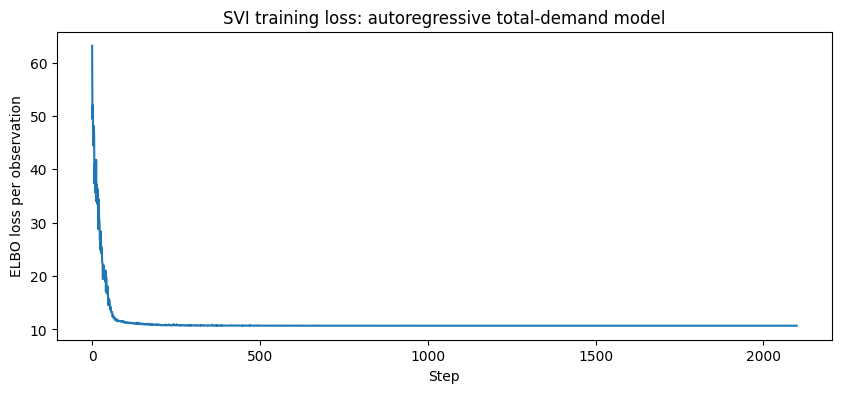

In [39]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(losses_ar)
ax.set_title("SVI training loss: autoregressive total-demand model")
ax.set_xlabel("Step")
ax.set_ylabel("ELBO loss per observation")
plt.show()

In [40]:
predictive_ar = Predictive(
    airport_model_ar_total,
    guide=guide_ar,
    num_samples=500,
    return_sites=("total", "outs")
)

samples_ar = predictive_ar(
    slot_test_ar,
    weekday_test_ar,
    lag_total_test_ar,
    None,
    None,
)

total_samples_ar = samples_ar["total"].detach().cpu().numpy()
outs_samples_ar = samples_ar["outs"].detach().cpu().numpy()

test_ar_df["pyro_ar_total_mean"] = total_samples_ar.mean(axis=0)
test_ar_df["pyro_ar_outs_mean"] = outs_samples_ar.mean(axis=0)
test_ar_df["pyro_ar_ins_mean"] = (
    test_ar_df["pyro_ar_total_mean"] - test_ar_df["pyro_ar_outs_mean"]
)
test_ar_df["pyro_ar_outs_share_mean"] = (
    test_ar_df["pyro_ar_outs_mean"] / np.maximum(test_ar_df["pyro_ar_total_mean"], 1)
)

In [41]:
test_ar_df["pyro_ar_total_q05"] = np.quantile(total_samples_ar, 0.05, axis=0)
test_ar_df["pyro_ar_total_q95"] = np.quantile(total_samples_ar, 0.95, axis=0)

test_ar_df["pyro_ar_outs_q05"] = np.quantile(outs_samples_ar, 0.05, axis=0)
test_ar_df["pyro_ar_outs_q95"] = np.quantile(outs_samples_ar, 0.95, axis=0)

outs_share_samples_ar = outs_samples_ar / np.maximum(total_samples_ar, 1)

test_ar_df["pyro_ar_outs_share_q05"] = np.quantile(
    outs_share_samples_ar, 0.05, axis=0
)

test_ar_df["pyro_ar_outs_share_q95"] = np.quantile(
    outs_share_samples_ar, 0.95, axis=0
)

In [42]:
pyro_ar_metrics = {
    "total_mae": mae(test_ar_df["total"], test_ar_df["pyro_ar_total_mean"]),
    "total_rmse": rmse(test_ar_df["total"], test_ar_df["pyro_ar_total_mean"]),
    "outs_mae": mae(test_ar_df["outs"], test_ar_df["pyro_ar_outs_mean"]),
    "outs_rmse": rmse(test_ar_df["outs"], test_ar_df["pyro_ar_outs_mean"]),
    "ins_mae": mae(test_ar_df["ins"], test_ar_df["pyro_ar_ins_mean"]),
    "ins_rmse": rmse(test_ar_df["ins"], test_ar_df["pyro_ar_ins_mean"]),
    "direction_mae": mae(
        test_ar_df["outs_share"],
        test_ar_df["pyro_ar_outs_share_mean"]
    ),
}

true_direction_ar = test_ar_df["outs"] > test_ar_df["ins"]
pred_direction_ar = test_ar_df["pyro_ar_outs_mean"] > test_ar_df["pyro_ar_ins_mean"]

pyro_ar_metrics["direction_accuracy"] = np.mean(
    true_direction_ar == pred_direction_ar
)

comparison.loc["pyro_ar_total_model"] = pyro_ar_metrics
comparison

,total_mae,total_rmse,outs_mae,outs_rmse,ins_mae,ins_rmse,direction_mae,direction_accuracy
global,31.144284,37.632649,22.237336,27.070677,16.414727,19.899338,0.222696,0.522773
slot,23.398850,29.866508,16.391825,22.595708,12.701343,15.734784,0.187874,0.664704
slot_weekday,21.045095,27.447879,14.858650,21.236757,11.559840,14.620317,0.174658,0.695500
pyro_slot_model,23.754593,30.256008,17.002605,22.947296,11.224933,14.745233,0.186098,0.672285
pyro_slot_weekday_model,21.967162,28.407036,16.309318,22.288258,10.344728,13.750735,0.186247,0.670805
pyro_ar_total_model,22.877698,29.341176,16.596051,22.589876,10.878758,14.274444,0.186247,0.670836


In [43]:
total_coverage_ar = np.mean(
    (test_ar_df["total"] >= test_ar_df["pyro_ar_total_q05"]) &
    (test_ar_df["total"] <= test_ar_df["pyro_ar_total_q95"])
)

outs_coverage_ar = np.mean(
    (test_ar_df["outs"] >= test_ar_df["pyro_ar_outs_q05"]) &
    (test_ar_df["outs"] <= test_ar_df["pyro_ar_outs_q95"])
)

share_coverage_ar = np.mean(
    (test_ar_df["outs_share"] >= test_ar_df["pyro_ar_outs_share_q05"]) &
    (test_ar_df["outs_share"] <= test_ar_df["pyro_ar_outs_share_q95"])
)

print(f"Total 90% coverage:      {total_coverage_ar:.3f}")
print(f"Outs 90% coverage:       {outs_coverage_ar:.3f}")
print(f"Out-share 90% coverage:  {share_coverage_ar:.3f}")

Total 90% coverage:      0.896
Outs 90% coverage:       0.793
Out-share 90% coverage:  0.495


# Model 4

*Does previous total traffic help predict current total traffic, and does previous directionality help predict current directionality?*

In [44]:
lag_dir_train_ar = torch.tensor(
    train_ar_df["logit_lag_outs_share_std"].values,
    dtype=torch.float32
)

lag_dir_test_ar = torch.tensor(
    test_ar_df["logit_lag_outs_share_std"].values,
    dtype=torch.float32
)

In [45]:
def airport_model_ar_total_direction(
    slot,
    weekday,
    lag_total,
    lag_dir,
    total_obs=None,
    outs_obs=None,
):
    n = len(slot)
    n_slots = 480
    n_weekdays = 7

    # global intercepts
    mu = pyro.sample("mu", dist.Normal(5.5, 1.0))
    eta = pyro.sample("eta", dist.Normal(0.0, 1.0))

    # autoregressive coefficients
    alpha_lag_total = pyro.sample("alpha_lag_total", dist.Normal(0.0, 0.5))
    gamma_lag_dir = pyro.sample("gamma_lag_dir", dist.Normal(0.0, 0.5))

    # hierarchical scales
    sigma_slot_total = pyro.sample("sigma_slot_total", dist.HalfNormal(1.0))
    sigma_slot_dir = pyro.sample("sigma_slot_dir", dist.HalfNormal(1.0))

    sigma_weekday_total = pyro.sample("sigma_weekday_total", dist.HalfNormal(0.5))
    sigma_weekday_dir = pyro.sample("sigma_weekday_dir", dist.HalfNormal(0.5))

    # overdispersion for total demand
    phi = pyro.sample("phi", dist.HalfNormal(10.0))

    # slot effects
    with pyro.plate("slots", n_slots):
        slot_total_raw = pyro.sample("slot_total_raw", dist.Normal(0.0, 1.0))
        slot_dir_raw = pyro.sample("slot_dir_raw", dist.Normal(0.0, 1.0))

    # weekday effects
    with pyro.plate("weekdays", n_weekdays):
        weekday_total_raw = pyro.sample("weekday_total_raw", dist.Normal(0.0, 1.0))
        weekday_dir_raw = pyro.sample("weekday_dir_raw", dist.Normal(0.0, 1.0))

    slot_total_effect = sigma_slot_total * slot_total_raw
    slot_dir_effect = sigma_slot_dir * slot_dir_raw

    weekday_total_effect = sigma_weekday_total * weekday_total_raw
    weekday_dir_effect = sigma_weekday_dir * weekday_dir_raw

    # total-demand model
    log_lambda = (
        mu
        + slot_total_effect[slot]
        + weekday_total_effect[weekday]
        + alpha_lag_total * lag_total
    )

    lambda_ = torch.exp(log_lambda)

    # directional model
    logits_p = (
        eta
        + slot_dir_effect[slot]
        + weekday_dir_effect[weekday]
        + gamma_lag_dir * lag_dir
    )

    with pyro.plate("data", n):
        total = pyro.sample(
            "total",
            dist.NegativeBinomial(
                total_count=phi,
                logits=torch.log(lambda_) - torch.log(phi)
            ),
            obs=total_obs,
        )

        binomial_total = total_obs if total_obs is not None else total

        pyro.sample(
            "outs",
            dist.Binomial(
                total_count=binomial_total,
                logits=logits_p
            ),
            obs=outs_obs,
        )

In [46]:
pyro.clear_param_store()

guide_ard = AutoNormal(airport_model_ar_total_direction)

optimizer = ClippedAdam({"lr": 0.01, "clip_norm": 10.0})
svi_ard = SVI(
    airport_model_ar_total_direction,
    guide_ard,
    optimizer,
    loss=Trace_ELBO()
)

losses_ard = []

num_steps = 2400

for step in range(num_steps):
    loss = svi_ard.step(
        slot_train_ar,
        weekday_train_ar,
        lag_total_train_ar,
        lag_dir_train_ar,
        total_train_ar,
        outs_train_ar,
    )

    losses_ard.append(loss / len(train_ar_df))

    if step % 300 == 0:
        print(f"step {step:04d} | loss per obs = {losses_ard[-1]:.2f}")

step 0000 | loss per obs = 54.42
step 0300 | loss per obs = 10.57
step 0600 | loss per obs = 10.52
step 0900 | loss per obs = 10.52
step 1200 | loss per obs = 10.52
step 1500 | loss per obs = 10.52
step 1800 | loss per obs = 10.52
step 2100 | loss per obs = 10.52


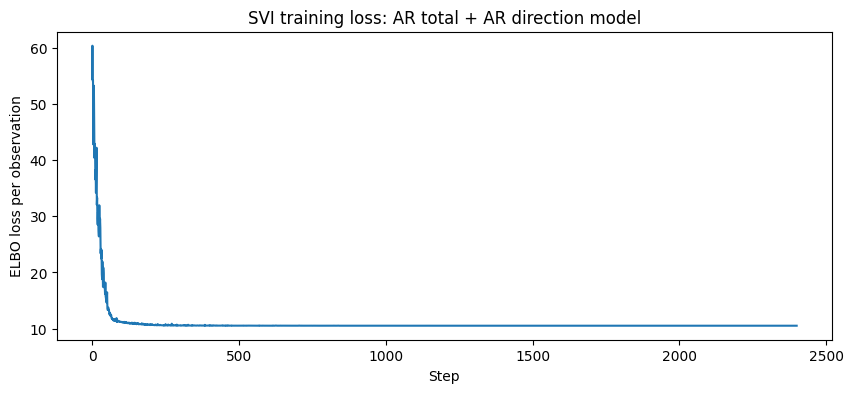

In [47]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(losses_ard)
ax.set_title("SVI training loss: AR total + AR direction model")
ax.set_xlabel("Step")
ax.set_ylabel("ELBO loss per observation")
plt.show()

Posterior predictive sampling:

In [48]:
predictive_ard = Predictive(
    airport_model_ar_total_direction,
    guide=guide_ard,
    num_samples=500,
    return_sites=("total", "outs")
)

samples_ard = predictive_ard(
    slot_test_ar,
    weekday_test_ar,
    lag_total_test_ar,
    lag_dir_test_ar,
    None,
    None,
)

total_samples_ard = samples_ard["total"].detach().cpu().numpy()
outs_samples_ard = samples_ard["outs"].detach().cpu().numpy()

In [49]:
test_ar_df["pyro_ard_total_mean"] = total_samples_ard.mean(axis=0)
test_ar_df["pyro_ard_outs_mean"] = outs_samples_ard.mean(axis=0)

test_ar_df["pyro_ard_ins_mean"] = (
    test_ar_df["pyro_ard_total_mean"] - test_ar_df["pyro_ard_outs_mean"]
)

test_ar_df["pyro_ard_outs_share_mean"] = (
    test_ar_df["pyro_ard_outs_mean"] / np.maximum(test_ar_df["pyro_ard_total_mean"], 1)
)

In [50]:
test_ar_df["pyro_ard_total_q05"] = np.quantile(total_samples_ard, 0.05, axis=0)
test_ar_df["pyro_ard_total_q95"] = np.quantile(total_samples_ard, 0.95, axis=0)

test_ar_df["pyro_ard_outs_q05"] = np.quantile(outs_samples_ard, 0.05, axis=0)
test_ar_df["pyro_ard_outs_q95"] = np.quantile(outs_samples_ard, 0.95, axis=0)

outs_share_samples_ard = outs_samples_ard / np.maximum(total_samples_ard, 1)

test_ar_df["pyro_ard_outs_share_q05"] = np.quantile(
    outs_share_samples_ard,
    0.05,
    axis=0
)

test_ar_df["pyro_ard_outs_share_q95"] = np.quantile(
    outs_share_samples_ard,
    0.95,
    axis=0
)

In [51]:
pyro_ard_metrics = {
    "total_mae": mae(test_ar_df["total"], test_ar_df["pyro_ard_total_mean"]),
    "total_rmse": rmse(test_ar_df["total"], test_ar_df["pyro_ard_total_mean"]),
    "outs_mae": mae(test_ar_df["outs"], test_ar_df["pyro_ard_outs_mean"]),
    "outs_rmse": rmse(test_ar_df["outs"], test_ar_df["pyro_ard_outs_mean"]),
    "ins_mae": mae(test_ar_df["ins"], test_ar_df["pyro_ard_ins_mean"]),
    "ins_rmse": rmse(test_ar_df["ins"], test_ar_df["pyro_ard_ins_mean"]),
    "direction_mae": mae(
        test_ar_df["outs_share"],
        test_ar_df["pyro_ard_outs_share_mean"]
    ),
}

true_direction_ard = test_ar_df["outs"] > test_ar_df["ins"]
pred_direction_ard = test_ar_df["pyro_ard_outs_mean"] > test_ar_df["pyro_ard_ins_mean"]

pyro_ard_metrics["direction_accuracy"] = np.mean(
    true_direction_ard == pred_direction_ard
)

comparison.loc["pyro_ar_total_direction_model"] = pyro_ard_metrics
comparison

,total_mae,total_rmse,outs_mae,outs_rmse,ins_mae,ins_rmse,direction_mae,direction_accuracy
global,31.144284,37.632649,22.237336,27.070677,16.414727,19.899338,0.222696,0.522773
slot,23.398850,29.866508,16.391825,22.595708,12.701343,15.734784,0.187874,0.664704
slot_weekday,21.045095,27.447879,14.858650,21.236757,11.559840,14.620317,0.174658,0.695500
pyro_slot_model,23.754593,30.256008,17.002605,22.947296,11.224933,14.745233,0.186098,0.672285
pyro_slot_weekday_model,21.967162,28.407036,16.309318,22.288258,10.344728,13.750735,0.186247,0.670805
pyro_ar_total_model,22.877698,29.341176,16.596051,22.589876,10.878758,14.274444,0.186247,0.670836
pyro_ar_total_direction_model,22.351898,28.761693,15.994879,21.839581,10.922327,14.363806,0.182507,0.682962


In [52]:
total_coverage_ard = np.mean(
    (test_ar_df["total"] >= test_ar_df["pyro_ard_total_q05"]) &
    (test_ar_df["total"] <= test_ar_df["pyro_ard_total_q95"])
)

outs_coverage_ard = np.mean(
    (test_ar_df["outs"] >= test_ar_df["pyro_ard_outs_q05"]) &
    (test_ar_df["outs"] <= test_ar_df["pyro_ard_outs_q95"])
)

share_coverage_ard = np.mean(
    (test_ar_df["outs_share"] >= test_ar_df["pyro_ard_outs_share_q05"]) &
    (test_ar_df["outs_share"] <= test_ar_df["pyro_ard_outs_share_q95"])
)

print(f"Total 90% coverage:      {total_coverage_ard:.3f}")
print(f"Outs 90% coverage:       {outs_coverage_ard:.3f}")
print(f"Out-share 90% coverage:  {share_coverage_ard:.3f}")

Total 90% coverage:      0.900
Outs 90% coverage:       0.803
Out-share 90% coverage:  0.504


In [53]:
posterior_ard = Predictive(
    airport_model_ar_total_direction,
    guide=guide_ard,
    num_samples=1000,
    return_sites=("alpha_lag_total", "gamma_lag_dir")
)

coef_samples = posterior_ard(
    slot_train_ar[:10],
    weekday_train_ar[:10],
    lag_total_train_ar[:10],
    lag_dir_train_ar[:10],
    None,
    None,
)

alpha_samples = coef_samples["alpha_lag_total"].detach().cpu().numpy()
gamma_samples = coef_samples["gamma_lag_dir"].detach().cpu().numpy()

print("alpha_lag_total:")
print("mean:", alpha_samples.mean())
print("90% CI:", np.quantile(alpha_samples, [0.05, 0.95]))

print("\ngamma_lag_dir:")
print("mean:", gamma_samples.mean())
print("90% CI:", np.quantile(gamma_samples, [0.05, 0.95]))

alpha_lag_total:
mean: -0.0024156272
90% CI: [-0.00426276 -0.00059089]

gamma_lag_dir:
mean: -0.3175192
90% CI: [-0.31913956 -0.31601155]


# Model 5: BetaBinomial for outs

In [54]:
def airport_model_ar_betabinomial(
    slot,
    weekday,
    lag_total,
    lag_dir,
    total_obs=None,
    outs_obs=None,
):
    n = len(slot)
    n_slots = 480
    n_weekdays = 7

    # global intercepts
    mu = pyro.sample("mu", dist.Normal(5.5, 1.0))
    eta = pyro.sample("eta", dist.Normal(0.0, 1.0))

    # autoregressive coefficients
    alpha_lag_total = pyro.sample("alpha_lag_total", dist.Normal(0.0, 0.5))
    gamma_lag_dir = pyro.sample("gamma_lag_dir", dist.Normal(0.0, 0.5))

    # hierarchical scales
    sigma_slot_total = pyro.sample("sigma_slot_total", dist.HalfNormal(1.0))
    sigma_slot_dir = pyro.sample("sigma_slot_dir", dist.HalfNormal(1.0))

    sigma_weekday_total = pyro.sample("sigma_weekday_total", dist.HalfNormal(0.5))
    sigma_weekday_dir = pyro.sample("sigma_weekday_dir", dist.HalfNormal(0.5))

    # overdispersion for total demand
    phi = pyro.sample("phi", dist.HalfNormal(10.0))

    # concentration controls directional overdispersion
    # larger kappa = closer to Binomial
    # smaller kappa = more extra variability
    kappa = pyro.sample("kappa", dist.Gamma(2.0, 0.1))

    with pyro.plate("slots", n_slots):
        slot_total_raw = pyro.sample("slot_total_raw", dist.Normal(0.0, 1.0))
        slot_dir_raw = pyro.sample("slot_dir_raw", dist.Normal(0.0, 1.0))

    with pyro.plate("weekdays", n_weekdays):
        weekday_total_raw = pyro.sample("weekday_total_raw", dist.Normal(0.0, 1.0))
        weekday_dir_raw = pyro.sample("weekday_dir_raw", dist.Normal(0.0, 1.0))

    slot_total_effect = sigma_slot_total * slot_total_raw
    slot_dir_effect = sigma_slot_dir * slot_dir_raw

    weekday_total_effect = sigma_weekday_total * weekday_total_raw
    weekday_dir_effect = sigma_weekday_dir * weekday_dir_raw

    # total-demand model
    log_lambda = (
        mu
        + slot_total_effect[slot]
        + weekday_total_effect[weekday]
        + alpha_lag_total * lag_total
    )

    lambda_ = torch.exp(log_lambda)

    # directional model
    logits_p = (
        eta
        + slot_dir_effect[slot]
        + weekday_dir_effect[weekday]
        + gamma_lag_dir * lag_dir
    )

    p = torch.sigmoid(logits_p)

    alpha_beta = p * kappa
    beta_beta = (1.0 - p) * kappa

    with pyro.plate("data", n):
        total = pyro.sample(
            "total",
            dist.NegativeBinomial(
                total_count=phi,
                logits=torch.log(lambda_) - torch.log(phi)
            ),
            obs=total_obs,
        )

        betabinomial_total = total_obs if total_obs is not None else total

        pyro.sample(
            "outs",
            dist.BetaBinomial(
                concentration1=alpha_beta,
                concentration0=beta_beta,
                total_count=betabinomial_total,
            ),
            obs=outs_obs,
        )

In [55]:
pyro.clear_param_store()

guide_bb = AutoNormal(airport_model_ar_betabinomial)

optimizer = ClippedAdam({"lr": 0.01, "clip_norm": 10.0})

svi_bb = SVI(
    airport_model_ar_betabinomial,
    guide_bb,
    optimizer,
    loss=Trace_ELBO()
)

losses_bb = []

num_steps = 2400

for step in range(num_steps):
    loss = svi_bb.step(
        slot_train_ar,
        weekday_train_ar,
        lag_total_train_ar,
        lag_dir_train_ar,
        total_train_ar,
        outs_train_ar,
    )

    losses_bb.append(loss / len(train_ar_df))

    if step % 300 == 0:
        print(f"step {step:04d} | loss per obs = {losses_bb[-1]:.2f}")

step 0000 | loss per obs = 50.98
step 0300 | loss per obs = 8.32
step 0600 | loss per obs = 8.31
step 0900 | loss per obs = 8.29
step 1200 | loss per obs = 8.29
step 1500 | loss per obs = 8.29
step 1800 | loss per obs = 8.29
step 2100 | loss per obs = 8.29


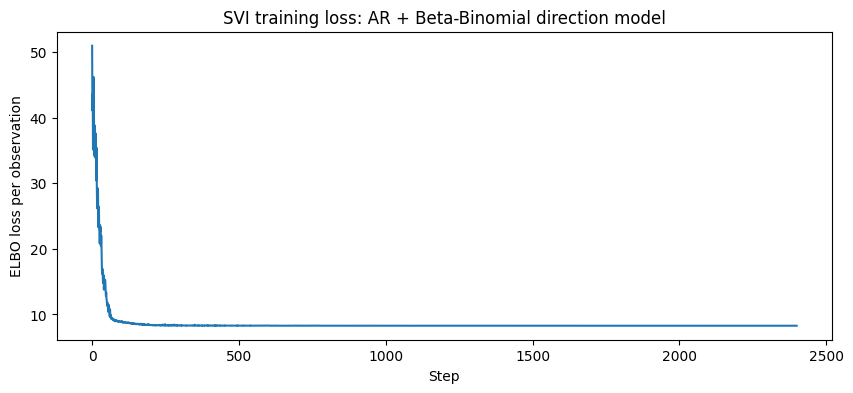

In [56]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(losses_bb)
ax.set_title("SVI training loss: AR + Beta-Binomial direction model")
ax.set_xlabel("Step")
ax.set_ylabel("ELBO loss per observation")
plt.show()

In [57]:
predictive_bb = Predictive(
    airport_model_ar_betabinomial,
    guide=guide_bb,
    num_samples=500,
    return_sites=("total", "outs")
)

samples_bb = predictive_bb(
    slot_test_ar,
    weekday_test_ar,
    lag_total_test_ar,
    lag_dir_test_ar,
    None,
    None,
)

total_samples_bb = samples_bb["total"].detach().cpu().numpy()
outs_samples_bb = samples_bb["outs"].detach().cpu().numpy()

In [58]:
test_ar_df["pyro_bb_total_mean"] = total_samples_bb.mean(axis=0)
test_ar_df["pyro_bb_outs_mean"] = outs_samples_bb.mean(axis=0)

test_ar_df["pyro_bb_ins_mean"] = (
    test_ar_df["pyro_bb_total_mean"] - test_ar_df["pyro_bb_outs_mean"]
)

test_ar_df["pyro_bb_outs_share_mean"] = (
    test_ar_df["pyro_bb_outs_mean"] / np.maximum(test_ar_df["pyro_bb_total_mean"], 1)
)

In [59]:
test_ar_df["pyro_bb_total_q05"] = np.quantile(total_samples_bb, 0.05, axis=0)
test_ar_df["pyro_bb_total_q95"] = np.quantile(total_samples_bb, 0.95, axis=0)

test_ar_df["pyro_bb_outs_q05"] = np.quantile(outs_samples_bb, 0.05, axis=0)
test_ar_df["pyro_bb_outs_q95"] = np.quantile(outs_samples_bb, 0.95, axis=0)

outs_share_samples_bb = outs_samples_bb / np.maximum(total_samples_bb, 1)

test_ar_df["pyro_bb_outs_share_q05"] = np.quantile(
    outs_share_samples_bb,
    0.05,
    axis=0
)

test_ar_df["pyro_bb_outs_share_q95"] = np.quantile(
    outs_share_samples_bb,
    0.95,
    axis=0
)

In [60]:
pyro_bb_metrics = {
    "total_mae": mae(test_ar_df["total"], test_ar_df["pyro_bb_total_mean"]),
    "total_rmse": rmse(test_ar_df["total"], test_ar_df["pyro_bb_total_mean"]),
    "outs_mae": mae(test_ar_df["outs"], test_ar_df["pyro_bb_outs_mean"]),
    "outs_rmse": rmse(test_ar_df["outs"], test_ar_df["pyro_bb_outs_mean"]),
    "ins_mae": mae(test_ar_df["ins"], test_ar_df["pyro_bb_ins_mean"]),
    "ins_rmse": rmse(test_ar_df["ins"], test_ar_df["pyro_bb_ins_mean"]),
    "direction_mae": mae(
        test_ar_df["outs_share"],
        test_ar_df["pyro_bb_outs_share_mean"]
    ),
}

true_direction_bb = test_ar_df["outs"] > test_ar_df["ins"]
pred_direction_bb = test_ar_df["pyro_bb_outs_mean"] > test_ar_df["pyro_bb_ins_mean"]

pyro_bb_metrics["direction_accuracy"] = np.mean(
    true_direction_bb == pred_direction_bb
)

comparison.loc["pyro_ar_betabinomial_model"] = pyro_bb_metrics
comparison

,total_mae,total_rmse,outs_mae,outs_rmse,ins_mae,ins_rmse,direction_mae,direction_accuracy
global,31.144284,37.632649,22.237336,27.070677,16.414727,19.899338,0.222696,0.522773
slot,23.398850,29.866508,16.391825,22.595708,12.701343,15.734784,0.187874,0.664704
slot_weekday,21.045095,27.447879,14.858650,21.236757,11.559840,14.620317,0.174658,0.695500
pyro_slot_model,23.754593,30.256008,17.002605,22.947296,11.224933,14.745233,0.186098,0.672285
pyro_slot_weekday_model,21.967162,28.407036,16.309318,22.288258,10.344728,13.750735,0.186247,0.670805
pyro_ar_total_model,22.877698,29.341176,16.596051,22.589876,10.878758,14.274444,0.186247,0.670836
pyro_ar_total_direction_model,22.351898,28.761693,15.994879,21.839581,10.922327,14.363806,0.182507,0.682962
pyro_ar_betabinomial_model,22.381235,28.849778,15.859638,21.785235,11.906613,15.216889,0.184239,0.676388


In [61]:
total_coverage_bb = np.mean(
    (test_ar_df["total"] >= test_ar_df["pyro_bb_total_q05"]) &
    (test_ar_df["total"] <= test_ar_df["pyro_bb_total_q95"])
)

outs_coverage_bb = np.mean(
    (test_ar_df["outs"] >= test_ar_df["pyro_bb_outs_q05"]) &
    (test_ar_df["outs"] <= test_ar_df["pyro_bb_outs_q95"])
)

share_coverage_bb = np.mean(
    (test_ar_df["outs_share"] >= test_ar_df["pyro_bb_outs_share_q05"]) &
    (test_ar_df["outs_share"] <= test_ar_df["pyro_bb_outs_share_q95"])
)

print(f"Total 90% coverage:      {total_coverage_bb:.3f}")
print(f"Outs 90% coverage:       {outs_coverage_bb:.3f}")
print(f"Out-share 90% coverage:  {share_coverage_bb:.3f}")

Total 90% coverage:      0.899
Outs 90% coverage:       0.863
Out-share 90% coverage:  0.871


In [62]:
posterior_bb = Predictive(
    airport_model_ar_betabinomial,
    guide=guide_bb,
    num_samples=1000,
    return_sites=("alpha_lag_total", "gamma_lag_dir", "kappa")
)

coef_samples_bb = posterior_bb(
    slot_train_ar[:10],
    weekday_train_ar[:10],
    lag_total_train_ar[:10],
    lag_dir_train_ar[:10],
    None,
    None,
)

alpha_samples_bb = coef_samples_bb["alpha_lag_total"].detach().cpu().numpy()
gamma_samples_bb = coef_samples_bb["gamma_lag_dir"].detach().cpu().numpy()
kappa_samples_bb = coef_samples_bb["kappa"].detach().cpu().numpy()

print("alpha_lag_total:")
print("mean:", alpha_samples_bb.mean())
print("90% CI:", np.quantile(alpha_samples_bb, [0.05, 0.95]))

print("\ngamma_lag_dir:")
print("mean:", gamma_samples_bb.mean())
print("90% CI:", np.quantile(gamma_samples_bb, [0.05, 0.95]))

print("\nkappa:")
print("mean:", kappa_samples_bb.mean())
print("90% CI:", np.quantile(kappa_samples_bb, [0.05, 0.95]))

alpha_lag_total:
mean: -0.0029083723
90% CI: [-0.00526622 -0.00036526]

gamma_lag_dir:
mean: -0.19877362
90% CI: [-0.20222128 -0.19535761]

kappa:
mean: 6.5437074
90% CI: [6.51204886 6.57503576]


# Plots

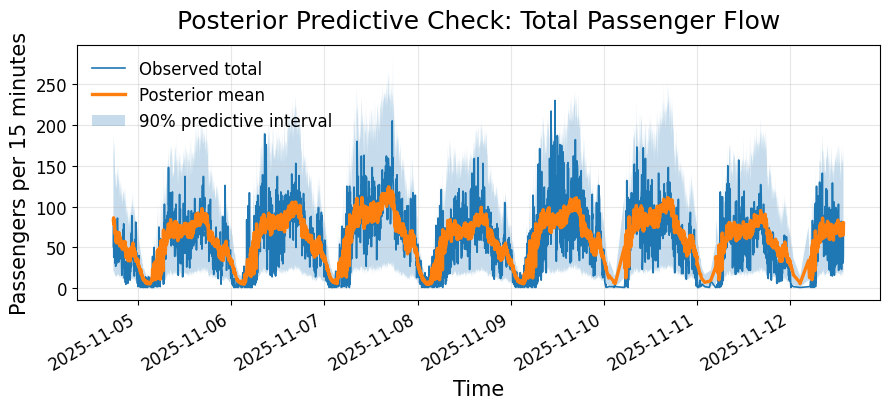

Saved figure to: figures_3min/posterior_predictive_total_flow.pdf


In [66]:
from pathlib import Path

FIG_DIR = Path("figures_3min")
FIG_DIR.mkdir(exist_ok=True)

FIG_PATH = FIG_DIR / "posterior_predictive_total_flow.pdf"

plot_df = test_ar_df.iloc[:7 * 480].copy()  # first test week
plot_df["timestamp"] = pd.to_datetime(plot_df["timestamp"], utc=True)

fig, ax = plt.subplots(figsize=(9, 4.2))

ax.plot(
    plot_df["timestamp"],
    plot_df["total"],
    label="Observed total",
    linewidth=1.2,
)

ax.plot(
    plot_df["timestamp"],
    plot_df["pyro_ard_total_mean"],
    label="Posterior mean",
    linewidth=2.4,
)

ax.fill_between(
    plot_df["timestamp"],
    plot_df["pyro_ard_total_q05"],
    plot_df["pyro_ard_total_q95"],
    alpha=0.25,
    label="90% predictive interval",
)

ax.set_title(
    "Posterior Predictive Check: Total Passenger Flow",
    fontsize=18,
    pad=12,
)
ax.set_xlabel("Time", fontsize=15)
ax.set_ylabel("Passengers per 15 minutes", fontsize=15)

ax.tick_params(axis="both", labelsize=12)
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=12, loc="best")

fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIG_PATH, bbox_inches="tight")
plt.show()

print(f"Saved figure to: {FIG_PATH}")

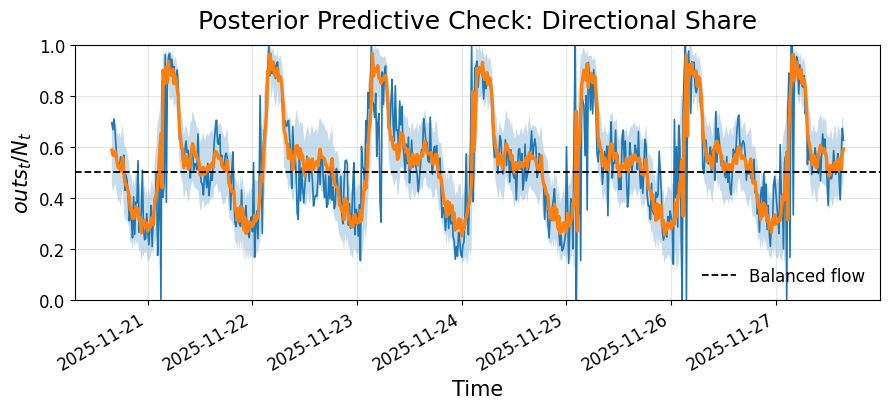

Saved figure to: figures/posterior_predictive_direction_share.pdf


In [ ]:
from pathlib import Path

FIG_DIR = Path("figures_3min")
FIG_PATH = FIG_DIR / "posterior_predictive_direction_share.pdf"

plot_df = test_ar_df.iloc[14 * 480:21 * 480].copy()
plot_df["timestamp"] = pd.to_datetime(plot_df["timestamp"], utc=True)


fig, ax = plt.subplots(figsize=(9, 4.2))

ax.plot(
    plot_df["timestamp"],
    plot_df["outs_share"],
    # label="Observed out-share",
    linewidth=1.2,
    label="_nolegend_",
)

ax.plot(
    plot_df["timestamp"],
    plot_df["pyro_bb_outs_share_mean"],
    # label="Posterior mean",
    linewidth=2.4,
    label="_nolegend_",
)

ax.fill_between(
    plot_df["timestamp"],
    plot_df["pyro_bb_outs_share_q05"],
    plot_df["pyro_bb_outs_share_q95"],
    alpha=0.25,
    # label="90% predictive interval",
    label="_nolegend_",
)

ax.axhline(
    0.5,
    linestyle="--",
    linewidth=1.3,
    color="black",
    label="Balanced flow",
)

ax.set_title(
    "Posterior Predictive Check: Directional Share",
    fontsize=18,
    pad=12,
)

ax.set_xlabel("Time", fontsize=15)
ax.set_ylabel(r"$outs_t / N_t$", fontsize=15)

ax.set_ylim(0, 1)
ax.tick_params(axis="both", labelsize=12)
ax.grid(alpha=0.3)

ax.legend(
    frameon=False,
    fontsize=12,
    loc="best",
)

fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIG_PATH, bbox_inches="tight")
plt.show()

print(f"Saved figure to: {FIG_PATH}")